# Assignment 9: Air Quality PM2.5 Prediction & Analysis
**Date:** 05/11/2026  
**Objective:** To build and evaluate machine learning models to predict PM2.5 concentrations using environmental parameters. Students will also perform data analysis, preprocessing, feature extraction, and dimensionality reduction using Pandas, NumPy, and Scikit-learn.

## 1. Load the given dataset
- Read the provided air quality dataset (having columns: Temperature, Humidity, PM2.5, PM10)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel('air_quality_data.xlsx')

## 2. Inspect the data
- Check the data shape, column names, missing values, and data types.
- Display the first 5 and last 5 records.
- Display the number of rows and columns.
- Display column names and data types.
- Check for missing values and duplicate records.
- Generate descriptive statistics using describe().
- Convert the Date column into the appropriate datetime format, if required.
- Select any one input feature (Temperature, Humidity, PM10) and consider PM2.5 as the output (dependent variable) for forecasting.

In [3]:
df.shape

(8760, 5)

In [4]:
df.columns

Index(['Date', 'Temperature', 'Humidity', 'PM2.5', 'PM10'], dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         8760 non-null   datetime64[us]
 1   Temperature  8760 non-null   float64       
 2   Humidity     8760 non-null   float64       
 3   PM2.5        8760 non-null   float64       
 4   PM10         8760 non-null   float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 342.3 KB


In [6]:
df.head()

,Date,Temperature,Humidity,PM2.5,PM10
0,2022-01-01 00:00:00,6.854305,1.961053,56.120565,140.328193
1,2022-01-01 01:00:00,32.782144,67.136801,59.609853,58.820015
2,2022-01-01 02:00:00,22.939727,52.315815,40.997973,71.128404
3,2022-01-01 03:00:00,16.939632,89.863893,83.848269,63.236436
4,2022-01-01 04:00:00,-2.979161,16.439268,18.517594,42.082053


In [7]:
df.tail()

,Date,Temperature,Humidity,PM2.5,PM10
8755,2022-12-31 19:00:00,28.457786,94.122164,39.967589,8.253635
8756,2022-12-31 20:00:00,0.372268,73.933620,72.180980,29.569313
8757,2022-12-31 21:00:00,4.740483,54.110292,95.300416,73.379260
8758,2022-12-31 22:00:00,-0.554822,93.261702,75.355858,23.647149
8759,2022-12-31 23:00:00,12.134418,47.843684,17.944866,103.907271


In [8]:
print("row:", df.shape[0])
print("column:", df.shape[1])

row: 8760
column: 5


In [9]:
df.isna().sum()

Date           0
Temperature    0
Humidity       0
PM2.5          0
PM10           0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,Date,Temperature,Humidity,PM2.5,PM10
count,8760,8760.000000,8760.000000,8760.000000,8760.000000
mean,2022-07-02 11:30:00,12.227369,50.154908,50.734174,74.402790
min,2022-01-01 00:00:00,-9.999476,0.005283,0.004812,0.000831
25%,2022-04-02 05:45:00,0.950413,25.221259,26.065142,36.912032
50%,2022-07-02 11:30:00,12.135590,50.258574,50.878727,74.531445
75%,2022-10-01 17:15:00,23.374345,75.441279,75.211026,110.907742
max,2022-12-31 23:00:00,34.987295,99.992483,99.990098,149.968406
std,NaN,12.978285,28.871321,28.762157,43.056552


In [12]:
print(df.dtypes)

Date           datetime64[us]
Temperature           float64
Humidity              float64
PM2.5                 float64
PM10                  float64
dtype: object


In [13]:
df['Date'] = pd.to_datetime(df['Date'])
df.head()

,Date,Temperature,Humidity,PM2.5,PM10
0,2022-01-01 00:00:00,6.854305,1.961053,56.120565,140.328193
1,2022-01-01 01:00:00,32.782144,67.136801,59.609853,58.820015
2,2022-01-01 02:00:00,22.939727,52.315815,40.997973,71.128404
3,2022-01-01 03:00:00,16.939632,89.863893,83.848269,63.236436
4,2022-01-01 04:00:00,-2.979161,16.439268,18.517594,42.082053


In [14]:
# Select any one input feature (Temperature, Humidity, PM10) and consider PM2.5 as the output (dependent variable) for forecasting
selected_feature = 'Temperature'
X_single = df[[selected_feature]]
y_target = df['PM2.5']

print(f"Selected Single Input Feature: {selected_feature}")
print(f"Target Variable (Dependent): PM2.5")

Selected Single Input Feature: Temperature
Target Variable (Dependent): PM2.5


## 3. Data Analysis Using Pandas and NumPy
- Calculate the average, maximum, and minimum values of Temperature, Humidity, PM2.5, and PM10.
- Group the data by month and calculate the average PM2.5.
- Filter records where PM2.5 exceeds a threshold specified by the student.
- Sort the dataset based on PM2.5 concentrations.
- Create a new column representing the month extracted from Date.
- Convert selected columns into NumPy arrays.
- Calculate the mean, median, standard deviation, maximum, and minimum.
- Identify records where PM2.5 is greater than its average.
- Calculate the correlation between selected environmental parameters.
- Apply array-based operations to create or modify features.

In [15]:
summary_stats = df[['Temperature', 'Humidity', 'PM2.5', 'PM10']].agg(['mean', 'max', 'min'])
print(summary_stats)

      Temperature   Humidity      PM2.5        PM10
mean    12.227369  50.154908  50.734174   74.402790
max     34.987295  99.992483  99.990098  149.968406
min     -9.999476   0.005283   0.004812    0.000831


In [16]:
monthly_avg = df.groupby(df['Date'].dt.to_period('M'))['PM2.5'].mean()
print(monthly_avg)

Date
2022-01    50.400937
2022-02    52.856629
2022-03    50.407450
2022-04    50.187030
2022-05    51.293350
2022-06    50.127378
2022-07    53.697545
2022-08    50.399111
2022-09    50.383435
2022-10    50.499758
2022-11    49.524397
2022-12    49.150902
Freq: M, Name: PM2.5, dtype: float64


In [17]:
# Filter records where PM2.5 exceeds a threshold specified by the student (e.g., threshold = 60 µg/m³)
threshold = 60
filtered_records = df[df['PM2.5'] > threshold]
print(f"Number of records where PM2.5 > {threshold}: {len(filtered_records)}")
filtered_records.head()

Number of records where PM2.5 > 60: 3607


,Date,Temperature,Humidity,PM2.5,PM10
3,2022-01-01 03:00:00,16.939632,89.863893,83.848269,63.236436
6,2022-01-01 06:00:00,-7.386237,79.196101,72.223326,49.835830
7,2022-01-01 07:00:00,28.977927,12.718119,90.397617,86.789470
8,2022-01-01 08:00:00,17.050176,39.855922,88.391840,36.005038
10,2022-01-01 10:00:00,-9.073698,25.472050,64.316145,116.129799


In [18]:
# Sort the dataset based on PM2.5 concentrations in descending order
df_sorted = df.sort_values(by='PM2.5', ascending=False)
df_sorted.head()

,Date,Temperature,Humidity,PM2.5,PM10
3523,2022-05-27 19:00:00,-5.455985,41.785619,99.990098,39.214618
1392,2022-02-28 00:00:00,-2.360894,28.021641,99.987144,107.379991
4313,2022-06-29 17:00:00,29.381013,54.423676,99.965631,122.774784
7161,2022-10-26 09:00:00,8.491981,92.813219,99.945052,78.252005
1992,2022-03-25 00:00:00,17.460132,55.776476,99.929948,102.216040


In [19]:
# Create a new column representing the month extracted from Date
df['Month'] = df['Date'].dt.month
df[['Date', 'Month', 'PM2.5']].head()

,Date,Month,PM2.5
0,2022-01-01 00:00:00,1,56.120565
1,2022-01-01 01:00:00,1,59.609853
2,2022-01-01 02:00:00,1,40.997973
3,2022-01-01 03:00:00,1,83.848269
4,2022-01-01 04:00:00,1,18.517594


In [20]:
# Convert selected columns into NumPy arrays
temp_array = df['Temperature'].to_numpy()
humidity_array = df['Humidity'].to_numpy()
pm25_array = df['PM2.5'].to_numpy()
pm10_array = df['PM10'].to_numpy()

print("Converted columns to NumPy arrays.")
print("Temperature array shape:", temp_array.shape)
print("PM2.5 array shape:      ", pm25_array.shape)

Converted columns to NumPy arrays.
Temperature array shape: (8760,)
PM2.5 array shape:       (8760,)


In [21]:
# Calculate the mean, median, standard deviation, maximum, and minimum using NumPy
print("PM2.5 Statistics (NumPy):")
print(f"Mean:               {np.mean(pm25_array):.4f}")
print(f"Median:             {np.median(pm25_array):.4f}")
print(f"Standard Deviation: {np.std(pm25_array):.4f}")
print(f"Maximum:            {np.max(pm25_array):.4f}")
print(f"Minimum:            {np.min(pm25_array):.4f}")

PM2.5 Statistics (NumPy):
Mean:               50.7342
Median:             50.8787
Standard Deviation: 28.7605
Maximum:            99.9901
Minimum:            0.0048


In [22]:
# Identify records where PM2.5 is greater than its average
pm25_average = df['PM2.5'].mean()
above_avg_records = df[df['PM2.5'] > pm25_average]

print(f"PM2.5 Average: {pm25_average:.4f}")
print(f"Total records where PM2.5 > average: {len(above_avg_records)}")
above_avg_records.head()

PM2.5 Average: 50.7342
Total records where PM2.5 > average: 4401


,Date,Temperature,Humidity,PM2.5,PM10,Month
0,2022-01-01 00:00:00,6.854305,1.961053,56.120565,140.328193,1
1,2022-01-01 01:00:00,32.782144,67.136801,59.609853,58.820015,1
3,2022-01-01 03:00:00,16.939632,89.863893,83.848269,63.236436,1
5,2022-01-01 05:00:00,-2.980247,80.410925,55.484219,134.256643,1
6,2022-01-01 06:00:00,-7.386237,79.196101,72.223326,49.835830,1


In [23]:
# Calculate the correlation between selected environmental parameters
correlation_matrix = df[['Temperature', 'Humidity', 'PM2.5', 'PM10']].corr()
print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
             Temperature  Humidity     PM2.5      PM10
Temperature     1.000000  0.008139  0.010380  0.009501
Humidity        0.008139  1.000000  0.001039 -0.001516
PM2.5           0.010380  0.001039  1.000000  0.008010
PM10            0.009501 -0.001516  0.008010  1.000000


In [24]:
# Apply array-based operations to create or modify features
# 1. Convert Temperature from Celsius to Kelvin using vectorized array addition
df['Temp_Kelvin'] = temp_array + 273.15

# 2. Create a binary indicator for high pollution (PM2.5 > 50) using np.where
df['High_Pollution_Flag'] = np.where(pm25_array > 50, 1, 0)

df[['Temperature', 'Temp_Kelvin', 'PM2.5', 'High_Pollution_Flag']].head()

,Temperature,Temp_Kelvin,PM2.5,High_Pollution_Flag
0,6.854305,280.004305,56.120565,1
1,32.782144,305.932144,59.609853,1
2,22.939727,296.089727,40.997973,0
3,16.939632,290.089632,83.848269,1
4,-2.979161,270.170839,18.517594,0


## 4. Pre-process the data
- Handle missing values, if any.
- Check for duplicate records.
- Apply appropriate feature scaling using StandardScaler or MinMaxScaler.
- Separate input features (X) and target variable (y).
- Consider PM2.5 as the dependent variable.

In [25]:
# Handle missing values, if any
print("Missing values count before handling:\n", df.isna().sum())
df = df.dropna()
print("\nMissing values after handling:\n", df.isna().sum())

# Check for duplicate records
print("\nDuplicate records before dropping:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate records after dropping:", df.duplicated().sum())

Missing values count before handling:
 Date                   0
Temperature            0
Humidity               0
PM2.5                  0
PM10                   0
Month                  0
Temp_Kelvin            0
High_Pollution_Flag    0
dtype: int64

Missing values after handling:
 Date                   0
Temperature            0
Humidity               0
PM2.5                  0
PM10                   0
Month                  0
Temp_Kelvin            0
High_Pollution_Flag    0
dtype: int64

Duplicate records before dropping: 0
Duplicate records after dropping: 0


## 5. Segmentation and Feature Extraction
### A. Segmentation
- Divide the hourly observations into four time intervals:
  - Morning: 6 AM–11 AM
  - Afternoon: 12 PM–5 PM
  - Evening: 6 PM–11 PM
  - Night: 12 AM–5 AM
- Extract the hour from the Date column.
- Assign each record to its corresponding time interval.
- Calculate the average PM2.5 concentration for each interval using Pandas.

### B. Feature Extraction: Create at least four new features using the existing dataset:
1. **Hour**: Extract the hour from the Date column.
2. **Month**: Extract the month from the Date column.
3. **Temperature-Humidity Difference**: Calculate the difference between Temperature and Humidity.
4. **PM10-to-PM2.5 Ratio**: Calculate the ratio of PM10 to PM2.5, handling zero values appropriately.

> **Important Note from PDF:** The PM10-to-PM2.5 ratio uses the target variable PM2.5. Do not use it as an input feature when predicting PM2.5, as this would cause target leakage. It can be calculated for exploratory analysis only.

In [26]:
# Extract the hour from the Date column
df['Hour'] = df['Date'].dt.hour

# Function to assign time intervals
def get_time_interval(hour):
    if 6 <= hour <= 11:
        return 'Morning'
    elif 12 <= hour <= 17:
        return 'Afternoon'
    elif 18 <= hour <= 23:
        return 'Evening'
    else: # 0 <= hour <= 5
        return 'Night'

# Assign each record to its corresponding time interval
df['Time_Interval'] = df['Hour'].apply(get_time_interval)

# Calculate the average PM2.5 concentration for each interval using Pandas
interval_avg_pm25 = df.groupby('Time_Interval')['PM2.5'].mean().reset_index()
interval_avg_pm25.columns = ['Time_Interval', 'Average_PM2.5']
print("Average PM2.5 Concentration by Time Interval:")
print(interval_avg_pm25)

Average PM2.5 Concentration by Time Interval:
  Time_Interval  Average_PM2.5
0     Afternoon      49.898255
1       Evening      51.434536
2       Morning      50.471292
3         Night      51.132612


In [27]:
# Feature Extraction: Create at least four new features
# 1. Hour (extracted from Date) - df['Hour']
# 2. Month (extracted from Date) - df['Month']
df['Month'] = df['Date'].dt.month

# 3. Temperature-Humidity Difference
df['Temp_Humidity_Diff'] = df['Temperature'] - df['Humidity']

# 4. PM10-to-PM2.5 Ratio (handling zero values in PM2.5 safely)
df['PM10_PM2.5_Ratio'] = np.where(df['PM2.5'] != 0, df['PM10'] / df['PM2.5'], 0.0)

print("Newly created features preview:")
df[['Date', 'Hour', 'Month', 'Temp_Humidity_Diff', 'PM10_PM2.5_Ratio']].head()

Newly created features preview:


,Date,Hour,Month,Temp_Humidity_Diff,PM10_PM2.5_Ratio
0,2022-01-01 00:00:00,0,1,4.893252,2.500477
1,2022-01-01 01:00:00,1,1,-34.354657,0.986750
2,2022-01-01 02:00:00,2,1,-29.376088,1.734925
3,2022-01-01 03:00:00,3,1,-72.924261,0.754177
4,2022-01-01 04:00:00,4,1,-19.418430,2.272544


In [28]:
# Separate input features (X) and target variable (y)
# As instructed, PM10_PM2.5_Ratio is excluded from input features to avoid target leakage
feature_cols = ['Temperature', 'Humidity', 'PM10', 'Hour', 'Month', 'Temp_Humidity_Diff']
X = df[feature_cols]
y = df['PM2.5']

print("Input Features (X):", feature_cols)
print("Target Variable (y): PM2.5")
print(f"Features matrix shape: {X.shape}, Target vector shape: {y.shape}")

# Apply appropriate feature scaling using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled features matrix shape:", X_scaled.shape)

Input Features (X): ['Temperature', 'Humidity', 'PM10', 'Hour', 'Month', 'Temp_Humidity_Diff']
Target Variable (y): PM2.5
Features matrix shape: (8760, 6), Target vector shape: (8760,)


Scaled features matrix shape: (8760, 6)


## 6. Feature Reduction
- Apply the PCA algorithm and select the top 2 features.

In [29]:
from sklearn.decomposition import PCA

# Apply PCA and select top 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio of top 2 components:", pca.explained_variance_ratio_)
print(f"Total variance explained: {np.sum(pca.explained_variance_ratio_):.4f}")

pca_df = pd.DataFrame(X_pca, columns=['Principal_Component_1', 'Principal_Component_2'])
pca_df.head()

Explained variance ratio of top 2 components: [0.33256628 0.17061213]
Total variance explained: 0.5032


,Principal_Component_1,Principal_Component_2
0,2.017862,-0.824676
1,0.223447,0.646543
2,0.450706,0.153265
3,-1.503187,0.223478
4,0.900707,-1.629717


## 7. Data Splitting
- Sequentially split the dataset into Training (80%) and Testing (20%) sets.
*(Sequential split maintains the chronological time-series order without shuffling).*

In [30]:
# Sequentially split the dataset into Training (80%) and Testing (20%) sets
train_size = int(0.80 * len(df))

X_train = X_pca[:train_size]
X_test = X_pca[train_size:]
y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print(f"Total dataset records:   {len(df)}")
print(f"Training samples (80%):  {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing samples (20%):   {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")

Total dataset records:   8760
Training samples (80%):  7008 (80.0%)
Testing samples (20%):   1752 (20.0%)


## 8. Model Training
- Train at least two machine learning models (e.g., Linear Regression, Random Forest, Support Vector Regression, or others).

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model 2: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Model 1: Linear Regression trained successfully.")
print("Model 2: Random Forest Regressor trained successfully.")

Model 1: Linear Regression trained successfully.
Model 2: Random Forest Regressor trained successfully.


## 9. Model Evaluation
- Evaluate the models using the following performance metrics:
  i. Root Mean Square Error (RMSE)
  ii. Mean Absolute Error (MAE)
  iii. R² Score

In [32]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Make predictions on testing set
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# Metrics for Linear Regression
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Metrics for Random Forest Regressor
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Summary performance table
eval_results = pd.DataFrame({
    'Performance Metric': ['Root Mean Square Error (RMSE)', 'Mean Absolute Error (MAE)', 'R² Score'],
    'Linear Regression': [rmse_lr, mae_lr, r2_lr],
    'Random Forest Regressor': [rmse_rf, mae_rf, r2_rf]
})
print("Model Evaluation Performance Summary:")
print(eval_results.to_string(index=False))

Model Evaluation Performance Summary:
           Performance Metric  Linear Regression  Random Forest Regressor
Root Mean Square Error (RMSE)          28.484523                30.728886
    Mean Absolute Error (MAE)          24.486553                25.845201
                     R² Score          -0.004769                -0.169343


## 10. Visualization
- Plot Actual vs. predicted PM2.5 for both models on the test data.
- Monthly average PM2.5 concentration.
- PM2.5 distribution using a histogram.
- Correlation heatmap of environmental parameters (optional).

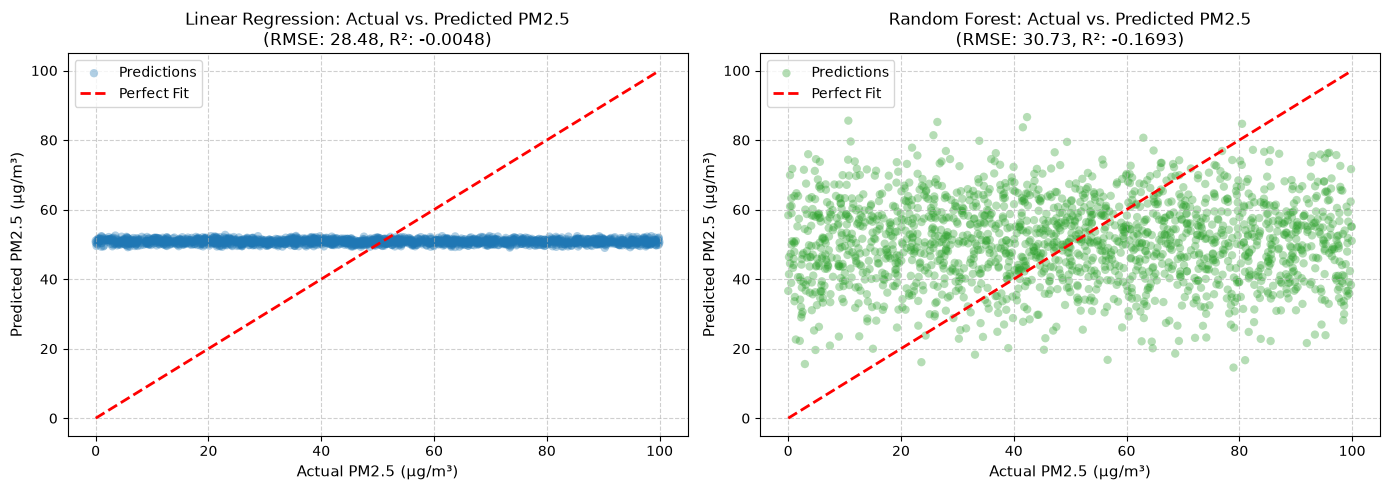

In [33]:
# 1. Plot Actual vs. predicted PM2.5 for both models on the test data
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Linear Regression
axes[0].scatter(y_test, y_pred_lr, alpha=0.35, color='#1f77b4', edgecolors='none', label='Predictions')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
axes[0].set_title(f'Linear Regression: Actual vs. Predicted PM2.5\n(RMSE: {rmse_lr:.2f}, R²: {r2_lr:.4f})', fontsize=12)
axes[0].set_xlabel('Actual PM2.5 (µg/m³)', fontsize=11)
axes[0].set_ylabel('Predicted PM2.5 (µg/m³)', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Random Forest Regressor
axes[1].scatter(y_test, y_pred_rf, alpha=0.35, color='#2ca02c', edgecolors='none', label='Predictions')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
axes[1].set_title(f'Random Forest: Actual vs. Predicted PM2.5\n(RMSE: {rmse_rf:.2f}, R²: {r2_rf:.4f})', fontsize=12)
axes[1].set_xlabel('Actual PM2.5 (µg/m³)', fontsize=11)
axes[1].set_ylabel('Predicted PM2.5 (µg/m³)', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

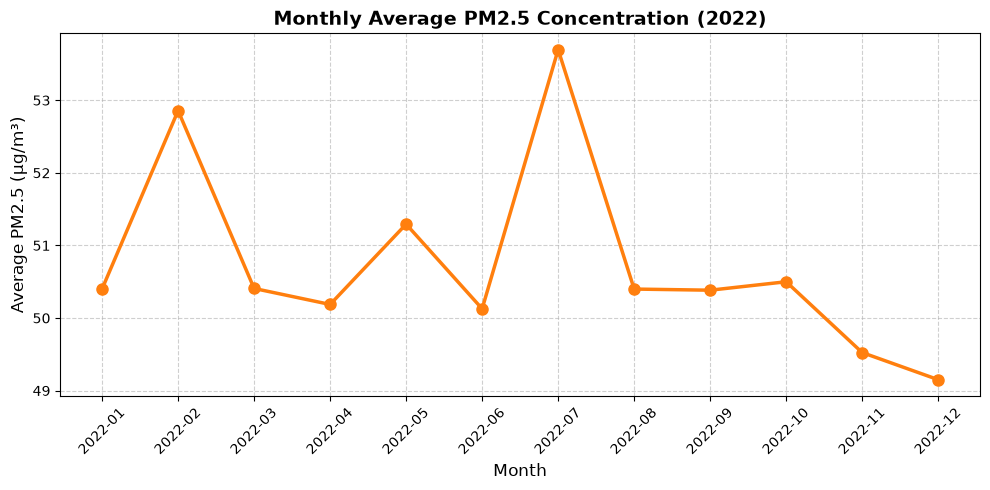

In [34]:
# 2. Monthly average PM2.5 concentration
monthly_data = df.groupby(df['Date'].dt.to_period('M'))['PM2.5'].mean().reset_index()
monthly_data['Date_Str'] = monthly_data['Date'].astype(str)

plt.figure(figsize=(10, 5))
plt.plot(monthly_data['Date_Str'], monthly_data['PM2.5'], marker='o', color='#ff7f0e', linewidth=2.5, markersize=8)
plt.title('Monthly Average PM2.5 Concentration (2022)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average PM2.5 (µg/m³)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

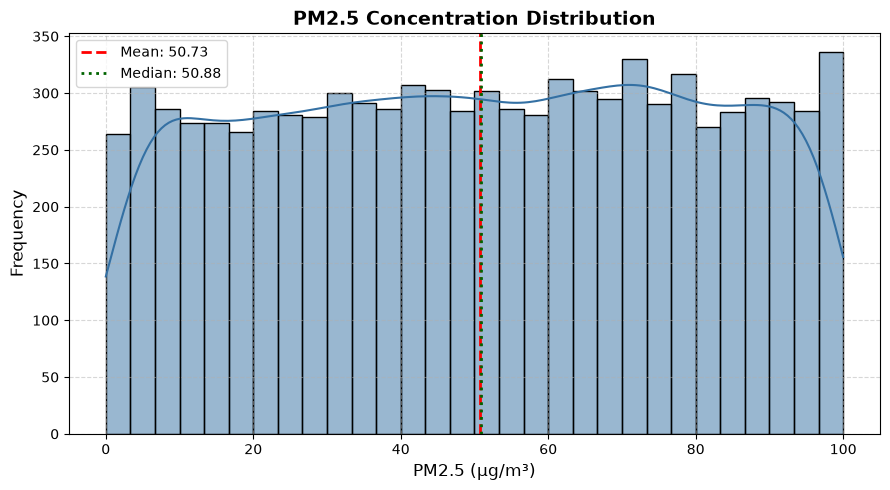

In [35]:
# 3. PM2.5 distribution using a histogram
plt.figure(figsize=(9, 5))
sns.histplot(df['PM2.5'], kde=True, bins=30, color='#3470a3', edgecolor='black')
plt.title('PM2.5 Concentration Distribution', fontsize=14, fontweight='bold')
plt.xlabel('PM2.5 (µg/m³)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.axvline(df['PM2.5'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["PM2.5"].mean():.2f}')
plt.axvline(df['PM2.5'].median(), color='darkgreen', linestyle=':', linewidth=2, label=f'Median: {df["PM2.5"].median():.2f}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

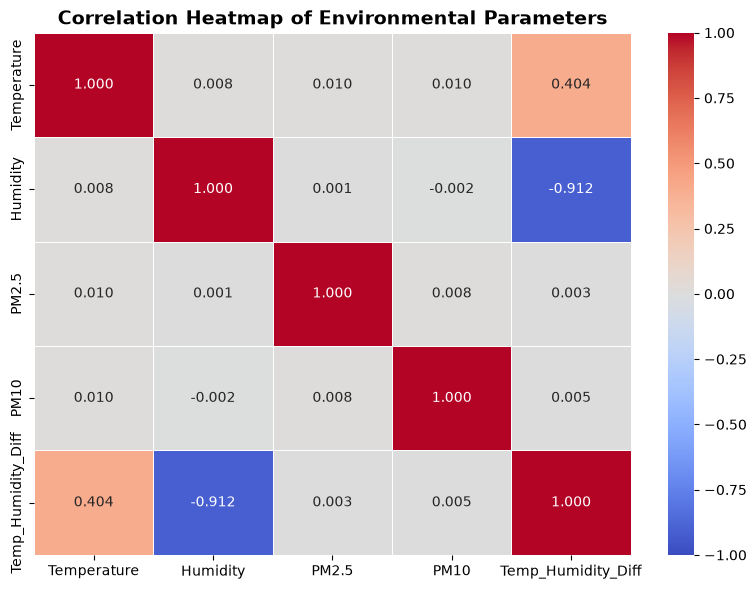

In [36]:
# 4. Correlation heatmap of environmental parameters (optional)
plt.figure(figsize=(8, 6))
env_columns = ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'Temp_Humidity_Diff']
sns.heatmap(df[env_columns].corr(), annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Environmental Parameters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()